In [ ]:
import numpy as np
from scipy import stats, integrate
from scipy.special import comb, betaln
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4.5)

## Exercise 1 – Quality Control in a Factory (Bayesian Inference)

### a) Probabilistic model
Let $X_i = 1$ if the $i$-th tested component is defective and $X_i = 0$ otherwise. Given $\theta$, the test outcomes are conditionally independent, so
$$X_i \mid \theta \sim \text{Bernoulli}(\theta), \quad i = 1,\dots,50 .$$
The number of defective components is the sum of independent Bernoulli variables with the same parameter, so
$$Y = \sum_{i=1}^{50} X_i \mid \theta \sim \text{Bin}(N = 50,\ \theta).$$
The **likelihood** of observing $y$ defective components is
$$P(Y = y \mid \theta) = \binom{N}{y}\theta^{y}(1-\theta)^{N-y}.$$
With our data, $N = 50$ and $y = 8$:
$$P(Y = 8 \mid \theta) = \binom{50}{8}\theta^{8}(1-\theta)^{42}.$$


In [ ]:
N, y = 50, 8          # components tested, defective components
a0, b0 = 2, 18        # prior Beta(2, 18)

def likelihood(theta):
    return comb(N, y) * theta**y * (1 - theta)**(N - y)

print(f"Y | theta ~ Bin({N}, theta)")
print(f"P(Y = {y} | theta) = C({N},{y}) * theta^{y} * (1-theta)^{N-y}")
print(f"Example: P(Y = 8 | theta = 0.16) = {likelihood(0.16):.4f}")

Y | theta ~ Bin(50, theta)
P(Y = 8 | theta) = C(50,8) * theta^8 * (1-theta)^42
Example: P(Y = 8 | theta = 0.16) = 0.1523


### b) Bayesian updating
By Bayes' theorem, the posterior is proportional to likelihood × prior:
$$p(\theta \mid y) \propto p(y \mid \theta)\, p(\theta).$$
The prior is $\theta \sim \text{Beta}(2, 18)$, so $p(\theta) \propto \theta^{2-1}(1-\theta)^{18-1}$. Multiplying by the likelihood:
$$p(\theta \mid y) \propto \theta^{8}(1-\theta)^{42} \cdot \theta^{1}(1-\theta)^{17} = \theta^{9}(1-\theta)^{59}.$$
This has the form of a Beta density, so the posterior is also a Beta distribution:
$$\theta \mid y \sim \text{Beta}(\alpha + y,\ \beta + N - y) = \text{Beta}(2+8,\ 18+42) = \text{Beta}(10,\ 60).$$

In [ ]:
a_post, b_post = a0 + y, b0 + N - y
prior = stats.beta(a0, b0)
posterior = stats.beta(a_post, b_post)

print(f"Prior:     Beta({a0}, {b0})")
print(f"Posterior: Beta({a0} + {y}, {b0} + {N} - {y}) = Beta({a_post}, {b_post})")

Prior:     Beta(2, 18)
Posterior: Beta(2 + 8, 18 + 50 - 8) = Beta(10, 60)


### c) Parameter estimation
- **MLE** (maximizes the likelihood): $\hat\theta_{\text{MLE}} = \dfrac{y}{N} = \dfrac{8}{50} = 0.16$
- **MAP** (mode of the posterior Beta$(a,b)$): $\hat\theta_{\text{MAP}} = \dfrac{a-1}{a+b-2} = \dfrac{9}{68} \approx 0.132$
- **Posterior mean**: $E[\theta \mid y] = \dfrac{\alpha+y}{\alpha+\beta+N} = \dfrac{10}{70} \approx 0.143$

**Comparison:** $\text{MAP} < \text{mean} < \text{MLE}$. The MLE uses only the data (16%), while the Bayesian estimates also include the prior, whose mean is 10%. This pulls them towards lower values, so they lie between 0.10 and 0.16.

In [ ]:
mle = y / N
map_est = (a_post - 1) / (a_post + b_post - 2)
post_mean = a_post / (a_post + b_post)

print(f"MLE            = {mle:.4f}")
print(f"MAP            = {map_est:.4f}")
print(f"Posterior mean = {post_mean:.4f}")

MLE            = 0.1600
MAP            = 0.1324
Posterior mean = 0.1429


### d) Visualization
We plot the prior $\text{Beta}(2,18)$ and the posterior $\text{Beta}(10,60)$ on the same graph, together with the three point estimates from (c).

**Interpretation:**
- The prior was centered around 0.10 (mode $1/18 \approx 0.056$) and fairly wide, which reflects vague previous knowledge.
- The data ($8/50 = 16\%$ defective) **move the distribution to the right**, toward higher defect rates.
- The posterior is also **much narrower**.


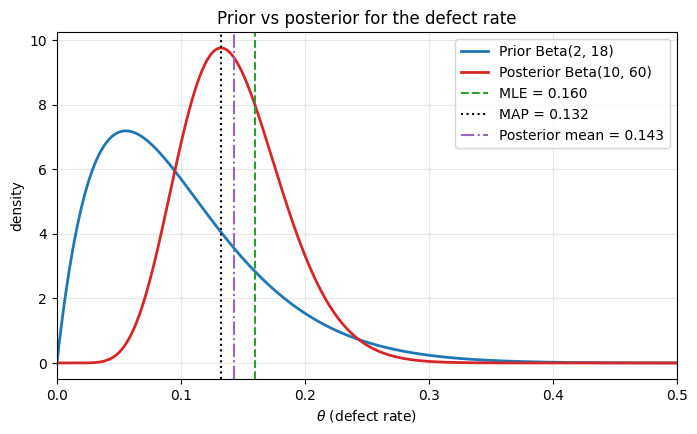

In [ ]:
plt.plot(theta, prior.pdf(theta), label="Prior Beta(2, 18)", color="tab:blue", lw=2)
plt.plot(theta, posterior.pdf(theta), label="Posterior Beta(10, 60)", color="tab:red", lw=2)
plt.axvline(mle, ls="--", color="tab:green", label=f"MLE = {mle:.3f}")
plt.axvline(map_est, ls=":", color="black", label=f"MAP = {map_est:.3f}")
plt.axvline(post_mean, ls="-.", color="tab:purple", label=f"Posterior mean = {post_mean:.3f}")
plt.xlim(0, 0.5)
plt.xlabel(r"$\theta$ (defect rate)"); plt.ylabel("density")
plt.title("Prior vs posterior for the defect rate")
plt.legend(); plt.grid(alpha=0.3); plt.show()



### e) Uncertainty – 95% credible interval
A central 95% credible interval leaves 2.5% of the posterior probability on each side:
$$P(\theta < \ell \mid y) = 0.025, \qquad P(\theta > u \mid y) = 0.025.$$
So $\ell$ and $u$ are the 2.5% and 97.5% quantiles of the posterior Beta(10, 60). Using `scipy.stats.beta`, we get $[0.072,\ 0.233]$.



In [ ]:
ci_low, ci_high = stats.beta.ppf([0.025, 0.975], a_post, b_post)
print(f"95% credible interval: [{ci_low:.3f}, {ci_high:.3f}]")

95% credible interval: [0.072, 0.233]


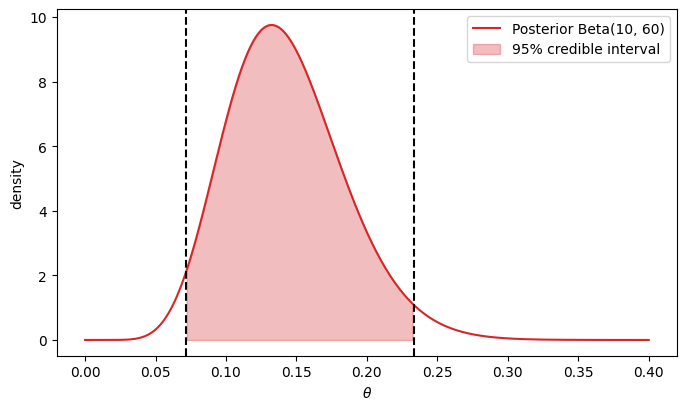

In [ ]:
theta = np.linspace(0, 0.4, 500)
plt.plot(theta, posterior.pdf(theta), color="tab:red", label="Posterior Beta(10, 60)")
mask = (theta >= ci_low) & (theta <= ci_high)
plt.fill_between(theta[mask], posterior.pdf(theta[mask]), alpha=0.3, color="tab:red", label="95% credible interval")
plt.axvline(ci_low, ls="--", color="black")
plt.axvline(ci_high, ls="--", color="black")
plt.xlabel(r"$\theta$"); plt.ylabel("density")
plt.legend(); plt.show()

### f) Practical decision
The factory wants $\theta < 0.10$. The posterior probability of this is the area under the posterior to the left of 0.10.
$$P(\theta < 0.10 \mid Y = 8) = \int_0^{0.10} p(\theta \mid y)\, d\theta = F_{\text{Beta}(10,60)}(0.10) \approx 0.148.$$

Before the data, this probability was about 0.58 (prior). After the data, it is only about 0.15, so there is around an 85% probability that the defect rate is **above** 10%.

In [ ]:
p_prior = stats.beta.cdf(0.10, a0, b0)
p_post = stats.beta.cdf(0.10, a_post, b_post)

print(f"Prior:     P(theta < 0.10)         = {p_prior:.3f}")
print(f"Posterior: P(theta < 0.10 | Y = 8) = {p_post:.3f}")

Prior:     P(theta < 0.10)         = 0.580
Posterior: P(theta < 0.10 | Y = 8) = 0.148


### g) Bayesian prediction
Let $X$ be the number of defective components among 10 new ones. If we knew $\theta$, the probability that none is defective would be $P(X = 0 \mid \theta) = (1-\theta)^{10}$. Since $\theta$ is unknown, we average this over the posterior (**posterior predictive distribution**):
$$P(X = 0 \mid Y = 8) = \int_0^1 (1-\theta)^{10}\, p(\theta \mid Y = 8)\, d\theta \approx 0.236.$$

**Interpretation:** there is about a 24% probability that all 10 new components are non-defective.

In [ ]:
p0, _ = integrate.quad(lambda t: (1 - t)**10 * stats.beta.pdf(t, a_post, b_post), 0, 1)
print(f"P(X = 0 | Y = 8) = {p0:.3f}")

P(X = 0 | Y = 8) = 0.236


## Exercise 2 – Opening a Fast-Food Restaurant (Monte Carlo Simulation)

### a) One-hour simulation
We work in minutes. For each simulated hour:
- **Arrivals:** the number of customers is $M \sim \text{Poisson}(\lambda \cdot 1\text{h}) = \text{Poisson}(20)$, and their arrival times $A_i$ are $M$ sorted uniform times on $[0, 60]$.
- **Service times:** payment $S_i \sim \text{Exp}(\text{mean } 2)$ and preparation $P_i \sim \text{Exp}(\text{mean } \alpha)$.

**Handling the two FIFO queues.** Customers are served in arrival order. A customer starts at a station when they are ready **and** the previous customer has left that station:
$$D_i = \max(A_i,\ D_{i-1}) + S_i \qquad \text{(end of payment)}$$
$$F_i = \max(D_i,\ F_{i-1}) + P_i \qquad \text{(food received)}$$


In [ ]:
def simulate_hour(alpha, rng):
    n = rng.poisson(20)                          # number of customers in one hour
    arrivals = np.sort(rng.uniform(0, 60, n))    # arrival times (minutes)
    pay = rng.exponential(2, n)                  # payment times, mean 2 min
    prep = rng.exponential(alpha, n)             # preparation times, mean alpha min

    pay_end = np.zeros(n)                        # when each customer finishes paying
    food = np.zeros(n)                           # when each customer gets the food
    for i in range(n):
        if i == 0:                               # first customer: no queue
            pay_end[i] = arrivals[i] + pay[i]
            food[i] = pay_end[i] + prep[i]
        else:                                    # wait for the previous customer if needed
            pay_end[i] = max(arrivals[i], pay_end[i-1]) + pay[i]
            food[i] = max(pay_end[i], food[i-1]) + prep[i]
    return arrivals, pay, prep, pay_end, food

# Example: one hour with alpha = 1 minute
rng = np.random.default_rng(123)
arrivals, pay, prep, pay_end, food = simulate_hour(1.0, rng)
print(f"Customers: {len(arrivals)}")
print(f"Max time until food: {np.max(food - arrivals):.2f} min")
print(f"Mean time until food: {np.mean(food - arrivals):.2f} min")

Customers: 22
Max time until food: 14.31 min
Mean time until food: 6.05 min


### b) Probability that every customer is served within 15 minutes
We use Monte Carlo simulation: for each value of $\alpha$, we simulate many hours and compute
$$\hat p(\alpha) = \frac{\text{number of hours where all customers get their food within 15 min}}{\text{number of simulated hours}}.$$
We try several values of $\alpha$ (grid search) and look for the largest one with $\hat p(\alpha) \ge 0.95$.



alpha = 0.0 | P(all customers) = 0.813 | P(one customer) = 0.953
alpha = 0.1 | P(all customers) = 0.809 | P(one customer) = 0.952
alpha = 0.2 | P(all customers) = 0.805 | P(one customer) = 0.951
alpha = 0.3 | P(all customers) = 0.800 | P(one customer) = 0.950
alpha = 0.4 | P(all customers) = 0.795 | P(one customer) = 0.948
alpha = 0.5 | P(all customers) = 0.789 | P(one customer) = 0.947
alpha = 1.0 | P(all customers) = 0.737 | P(one customer) = 0.934
alpha = 2.0 | P(all customers) = 0.446 | P(one customer) = 0.821
alpha = 3.0 | P(all customers) = 0.155 | P(one customer) = 0.579


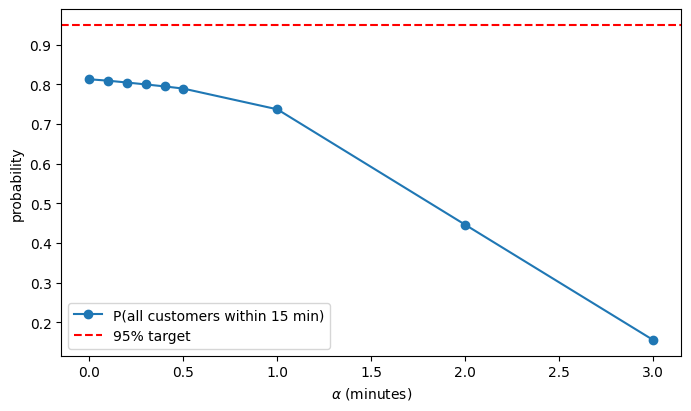

In [ ]:
N_SIM = 10_000    # number of simulated hours
SEED = 2026

def estimate(alpha):
    rng = np.random.default_rng(SEED)
    hours_ok = 0           # hours where ALL customers got food within 15 min
    customers_ok = 0       # customers who got food within 15 min
    customers_total = 0    # all customers
    for _ in range(N_SIM):
        arrivals, pay, prep, pay_end, food = simulate_hour(alpha, rng)
        t = food - arrivals                    # time until food for each customer
        if np.all(t <= 15):
            hours_ok += 1
        customers_ok += np.sum(t <= 15)
        customers_total += len(t)
    return hours_ok / N_SIM, customers_ok / customers_total

alphas = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 1, 2, 3]
p_all_list = []
for a in alphas:
    p_all, p_cust = estimate(a)
    p_all_list.append(p_all)
    print(f"alpha = {a:.1f} | P(all customers) = {p_all:.3f} | P(one customer) = {p_cust:.3f}")

plt.plot(alphas, p_all_list, "o-", label="P(all customers within 15 min)")
plt.axhline(0.95, color="red", ls="--", label="95% target")
plt.xlabel(r"$\alpha$ (minutes)"); plt.ylabel("probability")
plt.legend(); plt.show()

### c) Mean time between arrival and receipt of food
Part (b) showed that no $\alpha$ satisfies the 95% requirement for **all customers** (even $\alpha = 0$ gives only 0.81). To be able to answer this part, I use the largest $\alpha$ that reaches 95% for **one randomly chosen customer**: $\alpha = 0.3$ min, for which $P(\text{one customer} \le 15) = 0.950$.

For each customer we compute:
- the **total time** $T_i = F_i - A_i$ (from arrival until receiving the food),
- the **waiting time** $W_i = T_i - S_i - P_i$ (total time minus payment and preparation time).

We average them over all customers of all simulated hours.



In [ ]:
alpha_star = 0.3

rng = np.random.default_rng(SEED)
all_times = []  #total times
all_waits = []  #waiting times
all_pay = []
all_prep = []
for _ in range(N_SIM):
    arrivals, pay, prep, pay_end, food = simulate_hour(alpha_star, rng)
    t = food - arrivals                  # total time of each customer
    all_times.extend(t)
    all_waits.extend(t - pay - prep)     # waiting time (without service)
    all_pay.extend(pay)                  # payment times
    all_prep.extend(prep)                # preparation times

print(f"alpha = {alpha_star} min")
print(f"Mean time from arrival to food: {np.mean(all_times):.2f} min")
print(f"  - waiting in queues:          {np.mean(all_waits):.2f} min")
print(f"  - paying:                     {np.mean(all_pay):.2f} min")
print(f"  - cooking:                    {np.mean(all_prep):.2f} min")

alpha = 0.3 min
Mean time from arrival to food: 5.26 min
  - waiting in queues:          2.97 min
  - paying:                     1.99 min
  - cooking:                    0.30 min


**Result:** the mean total time is about **5.3 minutes**, of which about **3 minutes** is waiting in queues. The rest is service: about 2 minutes paying and 0.3 minutes cooking. Most of the waiting happens at the checkout, which is the bottleneck.

### d) Simulation settings and variability
- **Number of simulations:** 10,000 simulated hours for each value of $\alpha$.
- **Random seed:** 2026 , so the results are reproducible.
- **Search method:** grid search, trying $\alpha = 0, 0.1, 0.2, 0.3, 0.4, 0.5, 1, 2, 3$ and taking the largest value that reaches 95%.



In [ ]:
print(f"Number of simulations: {N_SIM} hours per alpha")
print(f"Random seed: {SEED}")
print("Search method: grid search over alpha = 0, 0.1, ..., 0.5, 1, 2, 3")

# Variability: same alpha, different seeds
alpha_star = 0.3
for s in [1, 2, 3, 4, 5]:
    rng = np.random.default_rng(s)
    hours_ok = 0
    for _ in range(N_SIM):
        arrivals, pay, prep, pay_end, food = simulate_hour(alpha_star, rng)
        if np.all(food - arrivals <= 15):
            hours_ok += 1
    print(f"seed = {s}: P(all customers within 15 min) = {hours_ok / N_SIM:.3f}")

Number of simulations: 10000 hours per alpha
Random seed: 2026
Search method: grid search over alpha = 0, 0.1, ..., 0.5, 1, 2, 3
seed = 1: P(all customers within 15 min) = 0.798
seed = 2: P(all customers within 15 min) = 0.799
seed = 3: P(all customers within 15 min) = 0.797
seed = 4: P(all customers within 15 min) = 0.797
seed = 5: P(all customers within 15 min) = 0.799


**Why the estimates vary between runs:** Monte Carlo estimates are based on random samples, so each run gives a slightly different result. With a different seed, we get different random arrivals and service times, and therefore slightly different probabilities. For example, with $\alpha = 0.3$ and five different seeds, the estimate of $P(\text{all customers} \le 15)$ varies between 0.797 and 0.799. The error decreases as the number of simulations increases , so more simulations give more precise results. The chosen $\alpha$ is especially sensitive, because near $\alpha = 0.3$ the probability for one customer is very close to 0.95.